# SwiftCart Online Retail Analytics using Python
## Sprint 1 – Data Understanding & Preparation

**Goal:** Convert the raw SwiftCart dataset into a clean, consistent, validated, analysis-ready dataset.

This notebook follows the project guide and uses Python, NumPy, Pandas, Matplotlib, Seaborn, and SciPy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

## 1. Business Understanding

### Business Objective
Understand customer behavior, product performance, sales patterns, order trends, and regional distribution so SwiftCart management can make better decisions.

### Analytical Objectives
- Understand the dataset and data quality.
- Clean and validate customer, order, product, sales, channel, date, and geographic fields.
- Identify initial customer, product, sales, order, and geographic observations.

### Expected Outcomes
A validated dataset that is suitable for EDA, statistical analysis, feature engineering, and business recommendations.

## 2. Dataset Loading

In [2]:
raw = pd.read_csv("SwiftCart_Store_Data_for_Students.csv")
raw.shape

(31047, 21)

### Question: What are the first and last records of the raw dataset?

In [3]:
raw.head()

,index,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
0,1.0,171-1029312-3038738,1029312.0,Women,NaN,Adult,"44,899.00",Dec,Delivered,Myntra,JNE1233-BLUE-KR-031-XXL,kurta,XXL,1,INR,376,MOHALI,PUNJAB,140301,IN,False
1,2.0,405-2183842-2225946,2183842.0,Women,29.0,Teenager,"44,899.00",Dec,Delivered,Ajio,SET414-KR-NP-L,Set,L,1,INR,1449,GURUGRAM,HARYANA,122002,IN,False
2,3.0,171-1641533-8921966,1641533.0,Women,67.0,Senior,"44,899.00",Dec,Delivered,Myntra,SET261-KR-PP-S,Set,S,1,INR,453,KOLKATA,WEST BENGAL,700029,IN,False
3,4.0,404-7490807-6300351,7490807.0,Women,20.0,Teenager,"44,899.00",Dec,Delivered,Amazon,SET110-KR-PP-M,Set,M,1,INR,729,THANJAVUR,TAMIL NADU,613007,IN,False
4,5.0,403-9293516-4577154,9293516.0,Women,62.0,Senior,"44,899.00",Dec,Delivered,Myntra,JNE2294-KR-A-XXL,kurta,XXL,1,INR,544,GURUGRAM,HARYANA,122001,IN,False


In [4]:
raw.tail()

,index,Order ID,Cust ID,Gender,Age,Age Group,Date,Month,Status,Channel,SKU,Category,Size,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,B2B
31042,31043.0,405-4724097-1016369,4724097.0,Men,60.0,Senior,"44,567.00",Jan,Delivered,Flipkart,J0083-KR-XL,kurta,XL,1,INR,565,PUNE,MAHARASHTRA,412307,IN,False
31043,31044.0,405-4724097-1016369,NaN,Men,NaN,Adult,"44,567.00",Jan,Delivered,Myntra,J0010-LCD-S,Set,S,1,INR,939,BENGALURU,KARNATAKA,560061,IN,False
31044,31045.0,408-3572295-5992330,3572295.0,Men,29.0,Teenager,"44,567.00",Jan,Delivered,Amazon,SET398-KR-PP-L,Set,L,1,INR,1115,PITHORAGARH,UTTARAKHAND,262501,IN,False
31045,31046.0,405-1423498-9705162,1423498.0,Men,46.0,Adult,"44,567.00",Jan,Delivered,Amazon,JNE3568-KR-M,kurta,M,1,INR,399,DHULE,MAHARASHTRA,424006,IN,False
31046,31047.0,408-4694875-8249153,4694875.0,Men,36.0,Adult,"44,567.00",Jan,Delivered,Flipkart,J0341-DR-XXXL,Western Dress,3XL,1,INR,791,WARANGAL,TELANGANA,506001,IN,False


**Observation:** The raw data contains 31,047 records and 21 columns. It includes order, customer, demographic, product, sales, channel, status, and shipping information.

## 3. Dataset Understanding

### Question: What are the columns and data types?

In [5]:
raw.dtypes

index                object
Order ID             object
Cust ID              object
Gender               object
Age                  object
Age Group            object
Date                float64
Month                object
Status               object
Channel              object
SKU                  object
Category             object
Size                 object
Qty                   int64
currency             object
Amount                int64
ship-city            object
ship-state           object
ship-postal-code      int64
ship-country         object
B2B                    bool
dtype: object

**Observation:** Several identifier/date fields are stored as object or numeric values that need appropriate preparation. `Age` contains text placeholders, while `Date` is stored as Excel-style numeric serials.

### Question: Which columns contain missing values?

In [6]:
raw.isna().sum().sort_values(ascending=False)

Age                 1085
index               1080
Order ID            1080
Cust ID             1079
Gender              1075
Age Group           1068
Date                 465
Month                465
Status                 0
Channel                0
SKU                    0
Category               0
Size                   0
Qty                    0
currency               0
Amount                 0
ship-city              0
ship-state             0
ship-postal-code       0
ship-country           0
B2B                    0
dtype: int64

**Observation:** Missing values are concentrated in `index`, `Order ID`, `Cust ID`, `Gender`, `Age`, `Age Group`, `Date`, and `Month`. No missing values occur in status, channel, SKU, category, size, quantity, amount, or geographic fields.

### Question: Are there exact duplicate records?

In [7]:
raw.duplicated().sum()

np.int64(0)

**Observation:** There are no exact duplicate rows. Repeated Order IDs are therefore treated as order-line structure rather than automatically deleted as duplicates.

### Question: What are the variable types and distinct category counts?

In [8]:
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique_values": raw.nunique(),
    "missing": raw.isna().sum()
}).sort_index()
summary

,dtype,unique_values,missing
Age,object,74,1085
Age Group,object,3,1068
Amount,int64,769,0
B2B,bool,2,0
Category,object,8,0
Channel,object,7,0
Cust ID,object,27493,1079
Date,float64,43,465
Gender,object,2,1075
Month,object,12,465


## 4. Data Cleaning

Cleaning decisions are based on the observed data. The raw file is never modified manually.

In [9]:
df = raw.copy()

# Standardize whitespace in text fields
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

# Remove the non-analytical row index column
df = df.drop(columns=["index"])

# Convert customer ID to nullable integer
df["Cust ID"] = pd.to_numeric(df["Cust ID"], errors="coerce").astype("Int64")

# Convert Age; invalid text and impossible ages are treated as missing
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df.loc[~df["Age"].between(18, 100), "Age"] = np.nan

# Postal code is an identifier, not a measure
df["ship-postal-code"] = df["ship-postal-code"].astype("Int64").astype(str).replace("<NA>", np.nan)

# Convert valid Excel serial dates; values outside the observed 2022 date range are invalid
raw_date = pd.to_numeric(df["Date"], errors="coerce")
df["Date"] = pd.NaT
valid_date = raw_date.between(40000, 50000)
df.loc[valid_date, "Date"] = pd.to_datetime(
    raw_date[valid_date], unit="D", origin="1899-12-30"
)

# Fill missing Month only where a valid Date provides the month
df["Month"] = df["Month"].where(df["Month"].notna(), df["Date"].dt.strftime("%b"))

df.dtypes

Order ID                    object
Cust ID                      Int64
Gender                      object
Age                        float64
Age Group                   object
Date                datetime64[ns]
Month                       object
Status                      object
Channel                     object
SKU                         object
Category                    object
Size                        object
Qty                          int64
currency                    object
Amount                       int64
ship-city                   object
ship-state                  object
ship-postal-code            object
ship-country                object
B2B                           bool
dtype: object

### Cleaning justification
- `index` was removed because it is a row-index artifact and is not unique or analytically meaningful.
- Text fields were stripped to remove formatting inconsistencies; 72 `ship-state` values had trailing spaces.
- `Cust ID` was converted to numeric with `errors='coerce'` because it is an identifier containing missing values.
- `Age` was converted to numeric. Six non-numeric placeholders were found, and 23 numeric ages above 100 were treated as invalid. They were not deleted; they were set to missing while the existing valid `Age Group` was retained.
- `Date` was converted from Excel serial format. 23 dates were outside the valid observed 2022 range and were treated as missing rather than inventing dates.
- `Month` was filled only from valid dates, avoiding unsupported reconstruction of missing dates.
- No exact duplicate rows were removed because none existed.`

## 5. Outlier Analysis

### Question: Are Quantity, Amount, and Age affected by unusual values?

In [10]:
df[["Qty", "Amount", "Age"]].describe(percentiles=[.01,.25,.50,.75,.95,.99]).T

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
Qty,"31,047.00",1.01,0.29,1.00,1.00,1.00,1.00,1.00,1.00,1.00,20.00
Amount,"31,047.00",682.07,268.58,229.00,292.00,486.00,646.00,794.00,"1,186.00","1,442.00","3,036.00"
Age,"29,933.00",39.48,15.11,18.00,18.00,28.00,37.00,47.00,71.00,77.00,78.00


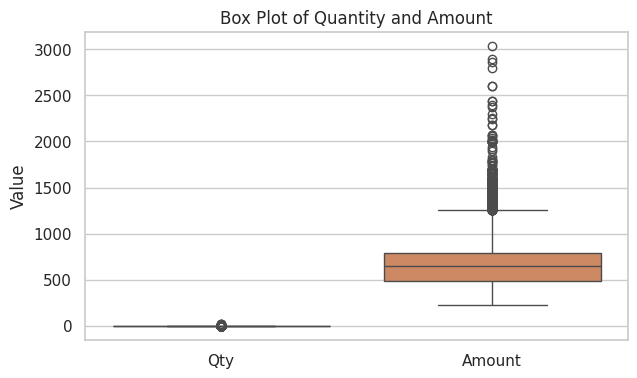

In [11]:
fig, ax = plt.subplots(figsize=(7,4))
sns.boxplot(data=df[["Qty", "Amount"]], ax=ax)
ax.set_title("Box Plot of Quantity and Amount")
ax.set_ylabel("Value")
plt.show()

**Observation:** Quantity is highly concentrated at 1, while a small number of higher quantities occur. Amount has a right tail but all values are positive. The unusual quantity values are retained because they are valid positive observations and may represent multi-unit purchases. Invalid ages were handled separately rather than treated as business outliers.

## 6. Categorical Validation

### Question: Are categorical values consistent after standardization?

In [12]:
categorical_cols = ["Gender","Age Group","Month","Status","Channel ","Category","Size","currency","ship-city","ship-state","ship-country"]
pd.DataFrame({
    "unique_after_cleaning": {c: df[c].nunique(dropna=True) for c in categorical_cols},
    "missing": {c: df[c].isna().sum() for c in categorical_cols}
})

,unique_after_cleaning,missing
Gender,2,1075
Age Group,3,1068
Month,12,8
Status,4,0
Channel,7,0
Category,8,0
Size,11,0
currency,1,0
ship-city,2603,0
ship-state,50,0


**Observation:** The main categorical fields contain stable categories. The only detected formatting inconsistency was trailing whitespace in one state representation.

## 7. Data Validation

### Question: Does the cleaned dataset satisfy the main quality checks?

In [13]:
validation = pd.DataFrame({
    "Check": [
        "Rows", "Columns", "Exact duplicate rows", "Missing Order ID",
        "Missing Customer ID", "Missing Age", "Missing Date", "Missing Month",
        "Negative Qty", "Zero Qty", "Negative Amount", "Zero Amount"
    ],
    "Result": [
        len(df), df.shape[1], df.duplicated().sum(), df["Order ID"].isna().sum(),
        df["Cust ID"].isna().sum(), df["Age"].isna().sum(), df["Date"].isna().sum(),
        df["Month"].isna().sum(), (df["Qty"]<0).sum(), (df["Qty"]==0).sum(),
        (df["Amount"]<0).sum(), (df["Amount"]==0).sum()
    ]
})
validation

,Check,Result
0,Rows,31047
1,Columns,20
2,Exact duplicate rows,0
3,Missing Order ID,1080
4,Missing Customer ID,1087
5,Missing Age,1114
6,Missing Date,488
7,Missing Month,8
8,Negative Qty,0
9,Zero Qty,0


**Observation:** The cleaned dataset has 31,047 rows and 20 columns, no exact duplicate records, positive quantity and amount values, consistent categories, and appropriately typed dates and identifiers. Some missing values remain where the source does not provide reliable information.

## 8. Initial Business Observations

In [14]:
initial = {
    "Total sales": df["Amount"].sum(),
    "Unique orders": df["Order ID"].nunique(),
    "Unique customers": df["Cust ID"].nunique(),
    "Top category by sales": df.groupby("Category")["Amount"].sum().idxmax(),
    "Top channel by sales": df.groupby("Channel ")["Amount"].sum().idxmax(),
    "Top state by sales": df.groupby("ship-state")["Amount"].sum().idxmax(),
    "Most common status": df["Status"].mode()[0],
    "Most common category by rows": df["Category"].mode()[0]
}
initial

{'Total sales': np.int64(21176377),
 'Unique orders': 27555,
 'Unique customers': 27490,
 'Top category by sales': 'Set',
 'Top channel by sales': 'Amazon',
 'Top state by sales': 'MAHARASHTRA',
 'Most common status': 'Delivered',
 'Most common category by rows': 'Set'}

**Observation:** These initial patterns identify the customer, product, sales, order, channel, and regional dimensions that should be investigated in Sprint 2. They are descriptive observations, not causal conclusions.

## 9. Save Cleaned Dataset

In [15]:
df.to_csv("SwiftCart_Cleaned_Dataset.csv", index=False)
print("Saved: SwiftCart_Cleaned_Dataset.csv")

Saved: SwiftCart_Cleaned_Dataset.csv
